# C02 — 캐리어 18번 LH 에어 누수 (2026-10-26, G-02-003)

정리본: [`cases/C02.md`](cases/C02.md). 이 노트북은 그 근거를 다시 만든다 (DB·재생은 캐시가 있으면 안 감).
C01과 같은 틀이다. C01에서 확정된 공통 결론(P0016F 0 고정, 주입 시간은 누수 피처가 아님, PLC 로직)은 [`cases/C01.md`](cases/C01.md) 5절을 참조하고 다시 증명하지 않는다.

| 단계 | 내용 |
|---|---|
| 1 | 일지 내용 (18번 과거 기록 포함) |
| 2 | 가동일 기록(하루 단위)을 운영 판정 함수에 넣기 |
| 3 | DB → 운영 코어 재생 — 통과 하나하나 (연속 가동 가정 10-16 ~ 10-28) |
| 4 | 모델 화면에 떴을 내용 — 연속 가동 재생 / 엣지와 같은 조건 재생(씨앗 기록 + 10-26 02:15 시작) |
| 5 | 실제 엣지 경고 (10-26 당일, 18번이 들어간 경고 W0098·W0172·W0242, W0073 대차 36 부분) |
| 6 | 유닛 사이클을 대차별로 — 조치 전후 |
| 7 | **딥 리서치 — 대차 18의 에어백 주입 시간은 왜 날마다 크게 흔들리나** (속도가 주입 도중 바뀜 · 0.5초 샘플링 · 6건 표 다시 계산) |

In [1]:
import sys, json; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from review_lib import paths, db, replay, backend, plot
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 40)
FIGS = paths.CHECK_DIRS["conveyor"] / "figs"; FIGS.mkdir(exist_ok=True)
WAGON = 18
SENSORS = ["P00140", "P00141", "P00154", "P00164", "P00451", "P00459"]
ACT = (pd.Timestamp("2026-10-26 11:00"), pd.Timestamp("2026-10-26 11:30"))
RCACHE = paths.CACHE_DIR / "replay"; RCACHE.mkdir(parents=True, exist_ok=True)
HIST = json.load(open(paths.MODEL_VERSIONS["v2.2"]["backend"] / "data" / "conveyor_core_history.json"))

## 1. 일지

In [2]:
acts = pd.read_csv(paths.ACTIONS_DIR / "actions_conveyor.csv")
acts[acts.incident_id == "C02"].T

,1
작업ID,G-02-003
incident_id,C02
domain,conveyor
작업일,2026-10-26
start_dt,2026-10-26 11:00:00
end_dt,2026-10-26 11:30:00
journal,공무반
sheet_src,CV
device_key,CONVEYOR
sub_unit,wagon


In [3]:
# 같은 대차 번호의 과거 기록 (`전체` 시트). 18번 기록은 모두 3라인이다 — 2라인 18번의 과거 기록은 없다.
full = pd.read_excel(paths.FILTERING_XLSX, sheet_name="전체")
txt = full[["설비상세", "이슈", "조치"]].fillna("").astype(str).agg(" ".join, axis=1)
full[txt.str.contains(r"18\s*번", regex=True)][["작업일", "라인번호", "공정표기", "설비분류", "설비상세", "조치", "기록시간", "작업ID"]]

,작업일,라인번호,공정표기,설비분류,설비상세,조치,기록시간,작업ID
6,2026-09-02,3,COLD,캐리어,캐리어(18번) 에어 누수,점검 및 조치,10:00~10:50,C-008
25,2026-09-09,3,COLD,온조기,온조기(18번) 불순환,점검 및 조치,10:00~10:50,C-033
27,2026-09-09,3,COLD,캐리어,캐리어(18번) 캐스터 파손,캐스터 교체,09:00~09:30,C-037
983,2026-10-26,2,COLD,캐리어,캐리어 ( 18번 LH ),에어누수로 인한 에어백점검 및 확인,11:00~11:30,G-02-003


## 2. 가동일 기록 → 운영 판정 (하루 단위)

`v2_2_1/backend/data/conveyor_core_history.json` — 09-10 ~ 10-19 씨앗(배치), 10-26 ~ 11-05 실시간 누적. **10-20 ~ 10-25 는 비어 있다.**
대차 18은 기록이 있는 41일 내내 6개 센서 모두 `정상`이다.

In [4]:
backend.use("v2.2")
from tools_yeji.conveyor_models.core_judge import judge
H = pd.DataFrame(HIST); H["day"] = pd.to_datetime(H.day)
J = judge(H)
w = J[J.wagon == WAGON]
print("대차 18 판정 (센서별 날 수):"); print(w.groupby(["sensor", "state"]).size().unstack(fill_value=0))
w[w.sensor.isin(["P00451", "P00459", "P00141"]) & (w.day >= "2026-10-10")].pivot_table(
    index="day", columns="sensor", values=["rearm", "rise_off", "width_ex"], aggfunc="first").round(2)

대차 18 판정 (센서별 날 수):
state   정상
sensor    
P00140  41
P00141  41
P00154  41
P00164  41
P00451  41
P00459  41


rearm               rise_off               width_ex              
sensor     P00141 P00451 P00459   P00141 P00451 P00459   P00141 P00451 P00459
day                                                                          
2026-10-10    0.0   0.20    0.0      0.0    0.0    0.0     0.00   0.00   0.00
2026-10-12    0.0   0.20    0.0      0.0    0.0    0.0    -1.00   0.00   0.00
2026-10-13    0.0   0.20    0.0      0.0   -1.0    0.0    -1.00   0.00   1.00
2026-10-14    0.0   0.30    0.0      0.0   -0.5    0.0    -1.00   1.00   0.00
2026-10-15    0.0   0.16    0.0      0.0    0.0    0.0     0.00   0.00   1.00
2026-10-16    0.0   0.21    0.0     -1.0   -1.0    0.0     0.00   0.00   0.00
2026-10-17    0.0   0.09    0.0      0.0   -1.0    0.0     0.00   0.50   0.00
2026-10-19    0.0   0.12    0.0     -1.0   -1.0    0.0     0.00   1.00   1.00
2026-10-26    0.0   0.08    0.0     -1.0   -1.0    0.0     0.75  -1.00   0.00
2026-10-27    0.0   0.07    0.0      0.0   -1.0    0.0     0.00   0.00   0.00
2026-10-28    0.0   0.09    0.0      0.0    0.0    0.0     0.00   0.00  -1.25
2026-10-29    0.0   0.09    0.0      0.0    0.0    0.0     1.00   0.00   0.00
2026-10-30    0.0   0.09    0.0      0.0    0.0    0.0     0.50   0.00   0.00
2026-10-31    0.0   0.02    0.0     -1.0    0.0    0.0     1.00   0.00  -0.50
2026-11-02    0.0   0.00    0.0     -1.0   -1.0    0.0     1.00   0.00   0.00
2026-11-03    0.0   0.00    0.0     -1.0   -1.0    0.0     0.00  -0.75  -1.00
2026-11-04    0.0   0.00    0.0     -1.0   -1.0    0.0     1.00   0.00   0.00
2026-11-05    0.0   0.00    0.0     -1.0   -1.0    0.0     1.00   0.50  -0.50

## 3. DB → 운영 코어 재생 (통과 하나하나)

두 가지로 돌린다. 둘 다 운영 코어 코드 그대로다(`replay.conveyor_core`). 처음 한 번은 각 5~10분.

| 이름 | 기록 | 구간 | 뜻 |
|---|---|---|---|
| `cont` | 10-16 이전 날 | 10-16 ~ 10-28 | 모델이 10-16부터 쉬지 않고 돌았다면 |
| `edge` | 10-19 이전 날(씨앗) | 10-26 02:15 ~ 11-05 | 엣지가 실제로 놓인 조건 (10-20~25 기록 공백, 10-26 02:15 시작 — C01 5절) |

In [5]:
TAGS = db.model_tags("conveyor", "v2.2")

def replay_cached(name, a, b, hist_before):
    f = RCACHE / f"c02_{name}.pkl"
    if f.exists():
        return pd.read_pickle(f)
    raw = db.fetch_range(a, b, TAGS, group="conveyor")
    P, E, core = replay.conveyor_core(raw, history=[r for r in HIST if r["day"] < hist_before],
                                      eval_every="15min", progress=False, units=("md_fwd", "md_rev", "airbag"))
    out = {"passes": P, "evals": E, "cycles": core.unit_cycles, "hz": raw[["Hz_In_Conv"]].rename(columns={"Hz_In_Conv": "Hz"})}
    pd.to_pickle(out, f)
    return out

CONT = replay_cached("cont_1016_1028", "2026-10-16", "2026-10-29", "2026-10-16")
EDGE = replay_cached("edge_1026_1105", "2026-10-26 02:15", "2026-11-06", "2026-10-20")

def add_dev(P):
    P = P.copy()
    P["day"] = (P.t - pd.Timedelta(hours=6)).dt.normalize()
    P = P.join(P.groupby(["day", "sensor"]).dist.median().rename("D"), on=["day", "sensor"])
    P = P.join(P.groupby(["day", "sensor"]).width.median().rename("W"), on=["day", "sensor"])
    P["front"] = P.dist - P.D          # 앞 끝 편차 (−: 표식보다 앞에서 켜짐)
    P["wex"] = P.width - P.W           # 켜짐 길이 편차
    return P

P = add_dev(CONT["passes"])
p18 = P[P.wagon == WAGON].sort_values("t")
p18.groupby([p18.day.dt.strftime("%m-%d"), "sensor"]).agg(
    n=("t", "size"), rearm=("rearm", "mean"), front=("front", "median"), wex=("wex", "median")).unstack().round(2)

n                                     rearm                                     front                                       wex                                   
sensor P00140 P00141 P00154 P00164 P00451 P00459 P00140 P00141 P00154 P00164 P00451 P00459 P00140 P00141 P00154 P00164 P00451 P00459 P00140 P00141 P00154 P00164 P00451 P00459
day                                                                                                                                                                           
10-15     3.0    3.0    3.0    2.0    2.0    NaN    0.0    0.0    0.0    0.0   0.50    NaN    0.0   -1.0    0.0    0.5   -4.5    NaN    0.0    0.0   -0.5    0.0    NaN    NaN
10-16   113.0  113.0  112.0  107.0  107.0  103.0    0.0    0.0    0.0    0.0   0.21    0.0    0.0   -1.0    0.0    0.0    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0
10-17    98.0   98.0   97.0   94.0   94.0   87.0    0.0    0.0    0.0    0.0   0.09    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
10-18     6.0    6.0    5.0    2.0    2.0    1.0    0.0    0.0    0.0    0.0   0.00    0.0    0.0   -1.0    0.0    0.0    0.0   -1.0   -0.5    1.0    0.5    0.0    0.0    0.0
10-19   102.0  102.0  102.0   96.0   96.0   93.0    0.0    0.0    0.0    0.0   0.11    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0    1.0
10-20   113.0  113.0  113.0  106.0  106.0  101.0    0.0    0.0    0.0    0.0   0.20    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.5
10-21   110.0  110.0  110.0  103.0  103.0  100.0    0.0    0.0    0.0    0.0   0.17    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0    1.0    0.0    0.0    0.0    1.0
10-22   103.0  103.0  103.0   98.0   98.0   92.0    0.0    0.0    0.0    0.0   0.12    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
10-23   104.0  104.0  104.0   95.0   95.0   93.0    0.0    0.0    0.0    0.0   0.18    0.0    0.0   -1.0    0.0    0.0    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0
10-24   109.0  109.0  109.0  102.0  102.0  100.0    0.0    0.0    0.0    0.0   0.18    0.0    0.0   -1.0    0.0    0.0    0.0    0.0   -1.0    0.0    1.0    0.0    0.0   -1.0
10-25     5.0    5.0    5.0    4.0    4.0    4.0    0.0    0.0    0.0    0.0   0.00    0.0    0.0    0.0    0.0    0.0    0.0    0.0    NaN    1.0    0.0   -1.0   -0.5   -3.0
10-26   101.0  101.0  100.0   89.0   89.0   86.0    0.0    0.0    0.0    0.0   0.08    0.0    0.0   -1.0    0.0    0.0    0.0    0.0   -1.0    0.0    0.0    0.0   -1.0   -1.0
10-27   103.0  103.0  102.0   99.0   99.0   97.0    0.0    0.0    0.0    0.0   0.08    0.0    0.0    0.0    0.0    0.0    0.0    0.0   -1.0    0.0    0.0    0.0    0.0    0.0
10-28   105.0  105.0  105.0   98.0   98.0   94.0    0.0    0.0    0.0    0.0   0.08    0.0    0.0    0.0    0.0    0.0    0.0    0.0   -1.0    0.0    1.0    0.0    0.0   -1.0

In [6]:
# 10-26 조치(11:00~11:30) 전후 — 6개 센서 모두 재감지 0, 앞 끝·길이 편차도 같다
q = p18[p18.t.between("2026-10-26 06:00", "2026-10-27 06:00")].copy()
q["조치"] = np.where(q.t < ACT[0], "전", "후")
q.groupby(["sensor", "조치"]).agg(n=("t", "size"), rearm=("rearm", "mean"), front=("front", "mean"),
                                 wex=("wex", "mean"), width_sd=("width", "std")).round(2).unstack()

n     rearm       front         wex       width_sd      
조치       전   후     전     후     전     후     전     후        전     후
sensor                                                           
P00140  28  73  0.00  0.00  0.00  0.00 -1.27 -0.91     0.65  1.15
P00141  28  73  0.00  0.00 -0.57 -0.59  0.43  0.00     0.85  1.17
P00154  28  72  0.00  0.00 -0.04 -0.01  0.40  0.40     0.83  1.06
P00164  26  63  0.00  0.00  0.19  0.10  0.54  0.27     0.97  1.13
P00451  26  63  0.15  0.05 -1.31 -0.33  0.33 -0.33     3.54  2.22
P00459  26  60  0.00  0.00  0.19  0.08 -0.67 -1.02     0.98  1.07

In [7]:
# 조치 시각은 오전 휴식 정지(10:52~11:32)와 겹친다 — 정지 직전·직후 각 센서를 지난 대차
x = P[P.t.between("2026-10-26 10:40", "2026-10-26 11:45")].sort_values("t")
pd.DataFrame({s: {"정지 전 마지막": f"{g[g.t < ACT[0]].t.max():%H:%M:%S} 대차 {int(g[g.t < ACT[0]].wagon.iloc[-1])}",
                  "재가동 첫 통과": f"{g[g.t > ACT[0]].t.min():%H:%M:%S} 대차 {int(g[g.t > ACT[0]].wagon.iloc[0])}"}
              for s, g in x.groupby("sensor")}).T

,정지 전 마지막,재가동 첫 통과
P00140,10:52:31 대차 34,11:00:11 대차 36
P00141,10:52:33 대차 34,11:00:12 대차 36
P00154,10:52:32 대차 33,11:00:41 대차 36
P00164,10:52:26 대차 8,11:32:23 대차 3
P00451,10:52:31 대차 8,11:32:27 대차 3
P00459,10:52:32 대차 36,11:35:29 대차 3


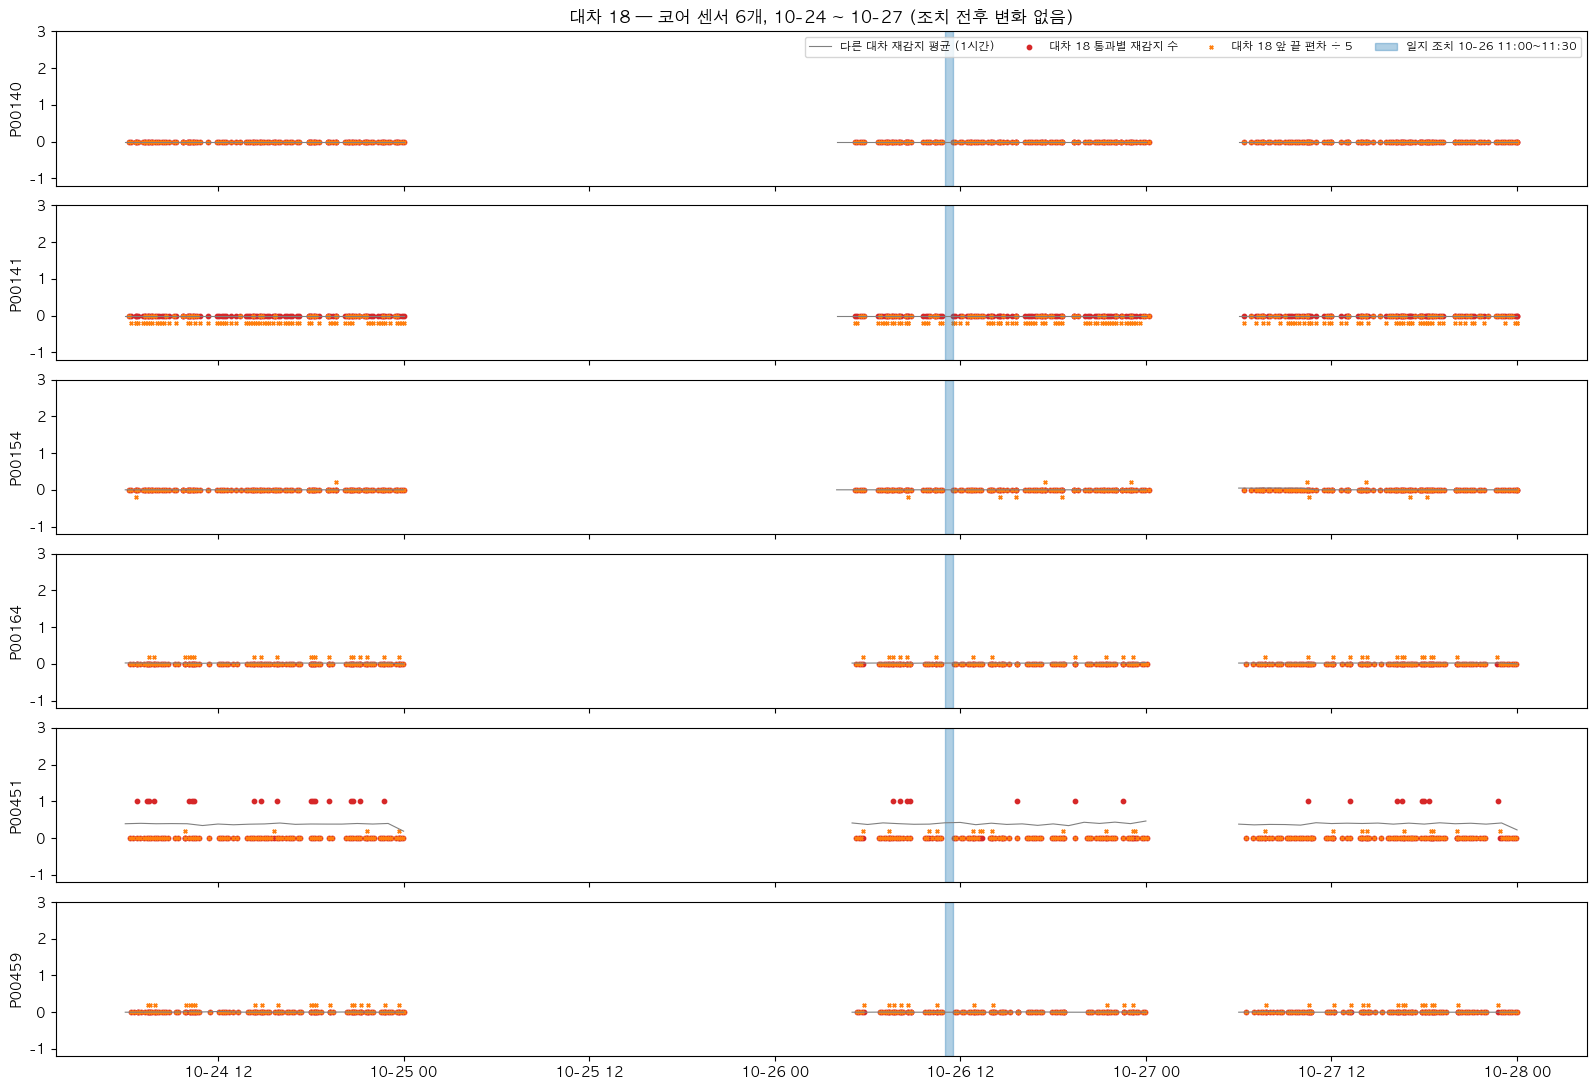

In [8]:
fig, axes = plt.subplots(len(SENSORS), 1, figsize=(16, 11), sharex=True)
win = ("2026-10-24 06:00", "2026-10-28 06:00")
for ax, s in zip(axes, SENSORS):
    q = p18[(p18.sensor == s) & p18.t.between(*win)]
    o = P[(P.sensor == s) & (P.wagon != WAGON) & P.t.between(*win)].set_index("t").rearm.resample("1h").mean()
    ax.plot(o.index, o.values, color="gray", lw=0.8, label="다른 대차 재감지 평균 (1시간)")
    ax.scatter(q.t, q.rearm, s=10, color="tab:red", label="대차 18 통과별 재감지 수")
    ax.scatter(q.t, q.front / 5, s=6, color="tab:orange", marker="x", label="대차 18 앞 끝 편차 ÷ 5")
    ax.axvspan(*ACT, color="tab:blue", alpha=0.35, label="일지 조치 10-26 11:00~11:30")
    ax.set_ylabel(s); ax.set_ylim(-1.2, 3)
axes[0].legend(loc="upper right", fontsize=8, ncol=4)
axes[0].set_title("대차 18 — 코어 센서 6개, 10-24 ~ 10-27 (조치 전후 변화 없음)")
fig.tight_layout(); fig.savefig(FIGS / "C02_wagon18_core.png", dpi=110, bbox_inches="tight")

## 4. 모델 화면에 떴을 내용 (재생 판정, 15분마다)

두 재생 모두 대차 18 항목이 몇 번 뜨는지 본다.

In [9]:
for name, R in [("cont", CONT), ("edge", EDGE)]:
    E = R["evals"]
    e18 = E[E.wagon == WAGON]
    print(f"[{name}] 대차 18 항목:", "없음" if e18.empty else "")
    if len(e18):
        print(e18.groupby(["sensor", "state"]).t.agg(["min", "max", "count"]))
    fl = E[E.wagon.isna() & (E["flags"].fillna("") != "")]
    print(f"[{name}] 센서 플래그:"); print(fl.groupby(["sensor", "flags"]).t.agg(["min", "max", "count"]), "\n")

[cont] 대차 18 항목: 없음
[cont] 센서 플래그:
                                     min                        max  count
sensor flags                                                              
P00451 센서 재감지 2026-10-16 08:02:01.687628 2026-10-28 23:46:14.896794   1208 

[edge] 대차 18 항목: 없음
[edge] 센서 플래그:
                                     min                        max  count
sensor flags                                                              
P00451 센서 재감지 2026-10-26 07:23:20.103134 2026-11-04 21:43:21.836382    685 



In [10]:
# 10-26 당일 재생 화면에 뜬 대차 항목 (센서·대차·상태별 처음·마지막)
for name, R in [("cont", CONT), ("edge", EDGE)]:
    E = R["evals"]; d = E[E.wagon.notna() & E.t.between("2026-10-26", "2026-10-27 06:00")]
    print(f"[{name}]"); print(d.groupby(["sensor", "wagon", "state"]).t.agg(["min", "max", "count"]), "\n")

[cont]
                                           min                        max  count
sensor wagon state                                                              
P00164 20.0  이물(분리) 2026-10-26 00:04:07.254955 2026-10-27 05:47:14.961793    119 

[edge]
                                           min                        max  count
sensor wagon state                                                              
P00164 20.0  이물(분리) 2026-10-26 07:23:20.103134 2026-10-27 05:47:14.961793     90
       40.0  이물(뒤)  2026-10-26 07:53:20.453063 2026-10-26 07:53:20.453063      1 



## 5. 실제 엣지 경고

컨베이어 경고 로그가 시작된 날이다(첫 경고 06:19). 10-26 당일 경고에 **대차 18은 한 번도 나오지 않는다.**
대차 18이 나오는 경고는 조치 뒤의 세 건뿐이다. 모두 `wagon_debris_back`(켜짐 길이 변화, 앞 끝 제자리)이다.

In [11]:
ep = pd.read_csv(paths.EPISODES_DIR / "warning_episodes.csv", low_memory=False)
cv = ep[ep.kind == "conveyor"]
day = cv[cv.onset.between("2026-10-26", "2026-10-27 06:00")]
print(day[["episode_id", "key", "onset", "last_detected", "wagon_nos", "reasons"]].to_string(), "\n")
has18 = cv[cv.wagon_nos.fillna("").astype(str).str.split(";").apply(lambda l: str(WAGON) in l)]
has18[["episode_id", "key", "onset", "last_detected", "wagon_nos", "reasons"]]

   episode_id            key                    onset            last_detected        wagon_nos                                reasons
63      W0064          drive  2026-10-26 06:19:05.750  2026-10-26 06:29:08.343              NaN                            drive_speed
68      W0069         P00451  2026-10-26 07:06:19.433  2026-10-31 20:25:55.822              NaN                           sensor_rearm
69      W0070  P00164:wagons  2026-10-26 07:06:19.433  2026-11-06 10:50:00.036               20         wagon_rearm;wagon_debris_front
70      W0071  P00140:wagons  2026-10-26 07:07:19.486  2026-10-26 13:08:07.381    6;19;28;32;37                      wagon_debris_back
72      W0073  P00459:wagons  2026-10-26 07:09:20.329  2026-10-26 11:43:43.064            28;36          wagon_rearm;wagon_debris_back
74      W0075  P00154:wagons  2026-10-26 07:19:22.768  2026-10-26 13:57:21.771  4;6;10;19;24;31                      wagon_debris_back
77      W0078  P00141:wagons  2026-10-26 08:42:42.288  

,episode_id,key,onset,last_detected,wagon_nos,reasons
97,W0098,P00459:wagons,2026-10-27 12:19:51.954,2026-10-27 16:47:07.909,2;18;19;22,wagon_debris_back
171,W0172,P00141:wagons,2026-10-31 23:35:57.287,2026-10-31 23:44:59.305,18,wagon_debris_back
241,W0242,P00141:wagons,2026-11-05 12:26:56.908,2026-11-05 15:33:47.960,18;33,wagon_debris_back


In [12]:
ev = pd.read_csv(paths.EPISODES_DIR / "warning_events.csv", low_memory=False, parse_dates=["ts"])
for eid, key, a, b in [("W0098", "P00459:wagons", "2026-10-27 12:00", "2026-10-27 20:00"),
                       ("W0172", "P00141:wagons", "2026-10-31 23:00", "2026-11-01 01:00"),
                       ("W0242", "P00141:wagons", "2026-11-05 12:00", "2026-11-05 20:00")]:
    e = ev[(ev.key == key) & ev.ts.between(a, b)]
    print(eid); print(e[["ts", "event", "wagon_nos", "message", "since"]].to_string(), "\n")

W0098
                          ts    event wagon_nos                                                 message  since
4520 2026-10-27 12:19:51.954   raised        22     후진Unit 캐리어 진입감지 대차 22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4536 2026-10-27 12:39:25.392  updated        22     후진Unit 캐리어 진입감지 대차 22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4537 2026-10-27 12:39:55.673  updated        22     후진Unit 캐리어 진입감지 대차 22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4548 2026-10-27 12:52:00.895  updated      2;22  후진Unit 캐리어 진입감지 대차 02·22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4563 2026-10-27 13:06:02.883  updated         2     후진Unit 캐리어 진입감지 대차 02: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4568 2026-10-27 13:12:33.653  updated         2     후진Unit 캐리어 진입감지 대차 02: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4574 2026-10-27 13:25:08.900  updated        22     후진Unit 캐리어 진입감지 대차 22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  10-27
4576 2026-10-27 13:29:40.079  updated        22     후진Unit 캐리어 진입감지 대차 22: 켜짐 길이 변화, 앞 끝 제자리 → 표식 뒤쪽 이물  1

In [13]:
# W0098 (10-27 P00459, 대차 2·18·19·22) — 엣지 조건 재생에서 그 시각 화면과 대차 18 통과
E = EDGE["evals"]
print(E[(E.sensor == "P00459") & E.wagon.notna() & E.t.between("2026-10-27 11:00", "2026-10-27 20:00")]
      .groupby(["wagon", "state"]).t.agg(["min", "max", "count"]))
PE = add_dev(EDGE["passes"])
q = PE[(PE.wagon == WAGON) & (PE.sensor == "P00459") & PE.t.between("2026-10-27 06:00", "2026-10-28 06:00")]
print(q[["t", "rearm", "front", "width", "wex"]].to_string())

Empty DataFrame
Columns: [min, max, count]
Index: []
                               t  rearm  front  width  wex
26784 2026-10-27 06:30:17.135524      0    0.0    8.0  0.0
27542 2026-10-27 06:57:59.272995      0    0.0    8.0  0.0
28045 2026-10-27 07:16:27.703131      0    0.0    8.0  0.0
28298 2026-10-27 07:25:41.888858      0    0.0    7.0 -1.0
28550 2026-10-27 07:34:56.354036      0    0.0    NaN  NaN
28800 2026-10-27 07:44:11.246405      0    0.0    8.0  0.0
28806 2026-10-27 07:44:26.173756      0    1.0    NaN  NaN
29306 2026-10-27 08:02:39.898547      0    0.0    7.0 -1.0
29556 2026-10-27 08:11:54.209614      0    0.0    8.0  0.0
30062 2026-10-27 08:30:22.358925      0    0.0    6.0 -2.0
30313 2026-10-27 08:39:36.848696      0    0.0    8.0  0.0
30565 2026-10-27 08:48:50.623041      0    0.0    NaN  NaN
30721 2026-10-27 09:09:24.225769      0    0.0    8.0  0.0
30974 2026-10-27 09:18:38.211595      0    0.0    7.0 -1.0
31226 2026-10-27 09:27:52.329548      0    0.0    6.0 -2.0
314

In [14]:
# W0172·W0242 (P00141, 10-31·11-05) — 대차 18 P00141 통과의 켜짐 길이
q = PE[(PE.wagon == WAGON) & (PE.sensor == "P00141")]
q.groupby(q.day.dt.strftime("%m-%d")).agg(n=("t", "size"), width=("width", "median"), wex_mean=("wex", "mean"),
                                         wex_min=("wex", "min"), short=("wex", lambda s: (s <= -2).mean()),
                                         nan=("width", lambda s: s.isna().mean())).round(2)

,n,width,wex_mean,wex_min,short,nan
day,,,,,,
10-25,5,9.0,0.75,0.0,0.00,0.20
10-26,101,8.0,0.13,-3.0,0.03,0.53
10-27,103,8.0,0.12,-2.0,0.01,0.51
10-28,106,8.0,-0.22,-2.0,0.02,0.57
10-29,113,8.0,0.37,-1.0,0.00,0.55
10-30,116,8.0,0.15,-3.0,0.03,0.59
10-31,112,8.0,0.25,-2.0,0.01,0.57
11-01,7,8.5,0.75,0.0,0.00,0.43
11-02,108,9.0,0.62,-1.0,0.00,0.49


In [15]:
# W0073 후반 (10:50 ~ 11:43, 대차 36 이물(뒤)) — 대차 36 P00459 통과
q = P[(P.wagon == 36) & (P.sensor == "P00459") & P.t.between("2026-10-25 06:00", "2026-10-27 06:00")]
print(q.groupby(q.day.dt.strftime("%m-%d")).agg(n=("t", "size"), width=("width", "median"), wex=("wex", "mean"),
                                                short=("wex", lambda s: (s <= -2).mean())).round(2))
print(CONT["evals"].query("wagon == 36 and sensor == 'P00459'").groupby("state").t.agg(["min", "max", "count"]))

        n  width   wex  short
day                          
10-25   7    9.0 -0.17   0.00
10-26  96    8.0  0.15   0.02
Empty DataFrame
Columns: [min, max, count]
Index: []


### 5-1. 엣지가 본 켜짐 길이는 DB 재생과 다르다

W0098·W0172·W0242와 W0073 대차 36 부분은 **엣지 조건 재생에서 하나도 재현되지 않는다.** 코어 코드는 v2.1(당시 엣지)과 v2.2가 같다(`core_realtime.py`·`core_judge.py`·`core_params.py` diff 없음).
엣지가 남긴 가동일 기록(10-26 ~ 11-04)과 재생으로 만든 칸을 비교한다.

In [16]:
Hd = pd.DataFrame(HIST); Hd["day"] = pd.to_datetime(Hd.day).dt.strftime("%m-%d")
PE["dkey"] = PE.day.dt.strftime("%m-%d")
cell = PE.groupby(["dkey", "sensor", "wagon"]).agg(n=("t", "size"), dist=("dist", "median"), width=("width", "median"),
                                                  rearm=("rearm", "mean")).reset_index().rename(columns={"dkey": "day"})
m = Hd.merge(cell, on=["day", "sensor", "wagon"], suffixes=("_edge", "_rep"))
m = m[m.day.between("10-26", "11-04")]
m["dw"] = m.width_edge - m.width_rep
print("앞 끝 위치 같음:", round((m.dist_edge == m.dist_rep).mean(), 3), "/ 켜짐 길이 같음:", round((m.dw == 0).mean(), 3),
      "/ 통과 수 엣지÷재생:", round(m.n_edge.sum() / m.n_rep.sum(), 3))
print("켜짐 길이 차이 (엣지 − 재생) 분포:"); print(m.dw.clip(-2, 2).value_counts(normalize=True).sort_index().round(3))
m[(m.wagon == WAGON) & (m.sensor == "P00141")][["day", "n_edge", "n_rep", "width_edge", "width_rep"]]

앞 끝 위치 같음: 0.989 / 켜짐 길이 같음: 0.726 / 통과 수 엣지÷재생: 1.025
켜짐 길이 차이 (엣지 − 재생) 분포:
dw
-1.5    0.000
-1.0    0.004
-0.5    0.004
 0.0    0.726
 0.5    0.064
 1.0    0.193
 1.5    0.002
 2.0    0.007
Name: proportion, dtype: float64


,day,n_edge,n_rep,width_edge,width_rep
234,10-26,103,101,9.0,8.0
291,10-27,105,103,8.0,8.0
622,10-28,107,106,8.0,8.0
793,10-29,111,113,9.0,8.0
1113,10-30,116,116,8.5,8.0
1461,10-31,112,112,9.0,8.0
1550,11-02,108,108,9.0,9.0
1826,11-03,93,94,8.0,8.0
2049,11-04,87,88,9.0,9.0


In [17]:
# W0098 (10-27 P00459) — 센서 전체의 켜짐 길이는 하루 내내 평탄하다. 대차 22 → 2 → 19 → 18로 하나씩 돌아가며 걸린 것
q = PE[(PE.sensor == "P00459") & PE.t.between("2026-10-27 06:00", "2026-10-28 06:00")].set_index("t")
pd.DataFrame({"전체 평균 길이": q.width.resample("1h").mean(), "9 이상 비율": q.width.ge(9).resample("1h").mean()}).round(2).T

t,2026-10-27 06:00:00,2026-10-27 07:00:00,2026-10-27 08:00:00,2026-10-27 09:00:00,2026-10-27 10:00:00,2026-10-27 11:00:00,2026-10-27 12:00:00,2026-10-27 13:00:00,2026-10-27 14:00:00,2026-10-27 15:00:00,2026-10-27 16:00:00,2026-10-27 17:00:00,2026-10-27 18:00:00,2026-10-27 19:00:00,2026-10-27 20:00:00,2026-10-27 21:00:00,2026-10-27 22:00:00,2026-10-27 23:00:00,2026-10-28 00:00:00
전체 평균 길이,8.33,8.11,8.11,8.37,8.05,7.81,8.02,8.16,8.06,8.10,8.22,8.13,8.21,8.18,8.06,8.06,8.30,8.21,8.27
9 이상 비율,0.23,0.23,0.23,0.28,0.25,0.23,0.22,0.21,0.23,0.23,0.25,0.25,0.25,0.23,0.22,0.24,0.28,0.27,0.26


In [18]:
# W0172·W0242 (P00141 대차 18) — 18번의 켜짐 길이(가동일 기록 중앙값)는 10월 동안 7 → 8 → 9로 서서히 늘었다. 10-26 계단은 아니다
x = J[J.sensor == "P00141"]
piv = x.pivot_table(index="wagon", columns=x.day.dt.strftime("%m-%d"), values="width_ex")
pre = piv[[c for c in piv.columns if "10-01" <= c <= "10-19"]].mean(axis=1)
post = piv[[c for c in piv.columns if c >= "10-27"]].mean(axis=1)
dd = (post - pre).sort_values()
print("P00141 켜짐 길이 편차, 10-27~11-05 평균 − 10-01~10-19 평균: 대차 18", round(dd[18], 2), "/ 42대 중앙값", round(dd.median(), 2),
      "/ 18번보다 작은 대차 비율", round((dd < dd[18]).mean(), 2))
Hd[(Hd.sensor == "P00141") & (Hd.wagon == WAGON) & (Hd.day >= "09-28")].set_index("day")[["n", "width"]].T

P00141 켜짐 길이 편차, 10-27~11-05 평균 − 10-01~10-19 평균: 대차 18 1.17 / 42대 중앙값 0.16 / 18번보다 작은 대차 비율 0.98


day,09-28,09-29,09-30,10-01,10-02,10-03,10-05,10-06,10-07,10-08,10-09,10-10,10-12,10-13,10-14,10-15,10-16,10-17,10-19,10-26,10-27,10-28,10-29,10-30,10-31,11-02,11-03,11-04,11-05
n,113.0,101.0,97.0,104.0,112.0,101.0,98.0,111.0,118.0,115.0,102.0,106.0,102.0,105.0,102.0,107.0,113.0,100.0,102.0,103.0,105.0,107.0,111.0,116.0,112.0,108.0,93.0,87.0,30.0
width,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,8.0,8.0,7.0,8.0,7.0,7.0,7.0,8.0,8.0,8.0,8.0,9.0,8.0,8.0,9.0,8.5,9.0,9.0,8.0,9.0,9.0


## 6. 유닛 사이클을 대차별로 — 조치 전후

세 에어 주입 유닛(에어백·전진·후진)의 사이클에 대차를 붙여(`replay.attach_wagon`) 18번과 나머지를 나눈다.
**원값을 그대로 비교하면 틀린다.** 후진 Unit에서 18번 주입 시간이 10-24부터 0.88 → 1.04~1.13초로 늘어 보이지만, 같은 날·같은 속도 경로(7절)의 평균을 빼면 차이가 없다.
아래는 원값과 속도 경로 보정 잔차를 함께 보인다.

In [19]:
C = CONT["cycles"]
hzc = CONT["hz"].Hz; hzc = hzc[~hzc.index.duplicated()]

def with_path(a, hz):
    ts, hv = hz.index.values.astype("datetime64[ns]"), hz.values
    a = a.copy(); a["t"] = a.t.astype("datetime64[ns]")
    i0 = np.searchsorted(ts, a.t.values, side="right") - 1
    i1 = np.searchsorted(ts, (a.t + pd.Timedelta(seconds=6)).values.astype("datetime64[ns]"), side="right") - 1
    a["path"] = [f"{round(hv[x:y + 1].max(), -1):.0f}→{round(hv[x:y + 1].min(), -1):.0f}" for x, y in zip(i0, i1)]
    return a

cols = ["stop_fwd_time", "catch_cnt", "drag_cnt", "air_time", "nozzle_rev_time", "nozzle_rev_time_1"]
raw_t, res_t = [], []
for u in ["airbag", "md_fwd", "md_rev"]:
    a = replay.attach_wagon(C, CONT["passes"], u)
    a = with_path(a[a.lag_s < 20].dropna(subset=["wagon"]), hzc)
    a["day"] = (a.t - pd.Timedelta(hours=6)).dt.normalize()
    a["구간"] = np.select([a.t < "2026-10-24 06:00", a.t < "2026-10-26 06:00", a.t < ACT[0], a.t < "2026-10-27 06:00"],
                        ["10-16~23", "10-24", "10-26 조치 전", "10-26 조치 후"], "10-27~28")
    cs = [c for c in cols if c in a and a[c].notna().any()]
    raw_t.append(a.assign(grp=np.where(a.wagon == WAGON, "18", "나머지")).groupby(["구간", "grp"])[cs].mean().assign(unit=u))
    for c in cs:
        g = a.groupby(["day", "path"])[c]
        a[c] = (a[c] - g.transform("mean")).where(g.transform("count") >= 50)
    res_t.append(a[a.wagon == WAGON].groupby("구간")[cs].mean().assign(unit=u))
print("원값 (18 vs 나머지):"); print(pd.concat(raw_t).round(3))
print("\n속도 경로 보정 잔차 (대차 18):")
pd.concat(res_t).round(3)

원값 (18 vs 나머지):
                stop_fwd_time  catch_cnt  drag_cnt  air_time  nozzle_rev_time_1    unit  nozzle_rev_time
구간         grp                                                                                          
10-16~23   18           0.261      6.692    31.882     2.536              0.309  airbag              NaN
           나머지          0.263      6.742    32.329     2.502              0.293  airbag              NaN
10-24      18           0.268      6.551    32.556     2.414              0.278  airbag              NaN
           나머지          0.267      6.720    32.334     2.488              0.295  airbag              NaN
10-26 조치 전 18           0.193      6.938    32.146     2.335              0.278  airbag              NaN
           나머지          0.271      6.732    32.234     2.515              0.300  airbag              NaN
10-26 조치 후 18           0.270      6.569    32.415     2.393              0.246  airbag              NaN
           나머지          0.258      6.76

,stop_fwd_time,catch_cnt,drag_cnt,air_time,nozzle_rev_time_1,unit,nozzle_rev_time
구간,,,,,,,
10-16~23,0.000,-0.097,-0.384,-0.048,0.022,airbag,NaN
10-24,-0.002,-0.028,0.232,0.041,-0.019,airbag,NaN
10-26 조치 전,-0.070,0.353,-0.266,-0.045,-0.014,airbag,NaN
10-26 조치 후,0.006,-0.015,0.004,0.014,-0.046,airbag,NaN
10-27~28,-0.017,-0.140,-0.180,-0.009,0.012,airbag,NaN
10-16~23,0.006,0.105,0.115,0.003,NaN,md_fwd,0.018
10-24,-0.022,0.412,-0.083,0.007,NaN,md_fwd,0.012
10-26 조치 전,0.034,-0.103,0.028,0.008,NaN,md_fwd,0.039
10-26 조치 후,0.013,-0.020,-0.001,0.020,NaN,md_fwd,0.006


## 7. 딥 리서치 — 대차 18의 에어백 주입 시간은 왜 날마다 크게 흔들리나

C01 5-1 표에서 대차 18의 "평소 흔들림"은 0.184초로 42대 가운데 가장 컸다(중앙값 0.045). 그래서 10-26 값(−0.6)이 흔들림 안이라는 판단도 약했다.

| 단계 | 확인 |
|---|---|
| 7-1 | 대차 18의 날별 주입 시간은 두 층으로 갈린다 — 그 갈림이 무엇과 같이 움직이나 |
| 7-2 | 주입 도중 속도가 바뀐다 — 다음 대차(19)의 제품 속도 |
| 7-3 | 0.5초 샘플링 — 주입 시간·노즐 후진 시간은 계단 값이다 |
| 7-4 | 속도 경로로 보정한 6건 표 (C01 5-1 다시 계산) |
| 7-5 | 부수: 대차 번호 태그가 한 틱 늦는 통과가 17% |
| 7-6 | 결론 |

에어백 유닛 사이클은 C01 캐시(`cache/replay/c01_units_*.pkl`, 09-10 ~ 10-27)를 그대로 쓴다.

In [20]:
PERIODS = [("2026-09-10", "2026-09-24"), ("2026-10-01", "2026-10-15"), ("2026-10-16", "2026-10-27")]
pers = [pd.read_pickle(RCACHE / f"c01_units_{a}_{b}.pkl") for a, b in PERIODS]   # C01 노트북 7-3이 만든 캐시
hz = pd.concat([p["hz"] for p in pers]).sort_index(); hz = hz[~hz.index.duplicated()].Hz

def airbag_table(per):
    a = replay.attach_wagon(per["cycles"], per["passes"], "airbag").dropna(subset=["wagon"])
    a = a[a.lag_s < 20].copy(); a["t"] = a.t.astype("datetime64[ns]"); a["wagon"] = a.wagon.astype(int)
    a["day"] = (a.t - pd.Timedelta(hours=6)).dt.normalize()
    return a

AB = pd.concat([airbag_table(p) for p in pers], ignore_index=True).sort_values("t")
# 스톱퍼 ON 시점 속도(C01 방식)와, 스톱퍼 ON ~ +6초(주입이 끝나는 시각보다 뒤) 동안의 최저·최고 속도
ts, hv = hz.index.values.astype("datetime64[ns]"), hz.values
i0 = np.searchsorted(ts, AB.t.values, side="right") - 1
i1 = np.searchsorted(ts, (AB.t + pd.Timedelta(seconds=6)).values.astype("datetime64[ns]"), side="right") - 1
AB["hz0"] = hv[i0]
AB["hz_min"] = [hv[a:b + 1].min() for a, b in zip(i0, i1)]
AB["hz_max"] = [hv[a:b + 1].max() for a, b in zip(i0, i1)]
AB["hzb"] = AB.hz0.round(-1)
AB["path"] = AB.hz_max.round(-1).astype(int).astype(str) + "→" + AB.hz_min.round(-1).astype(int).astype(str)
AB["chg"] = (AB.hz_max - AB.hz_min) >= 5
print("전체 사이클 중 주입 도중 속도가 바뀐 비율:", round(AB.chg.mean(), 3))
AB.path.value_counts().head(8)

전체 사이클 중 주입 도중 속도가 바뀐 비율: 0.385


path
400→400    84223
400→320    23070
400→360    17489
400→380     6665
360→320     2713
380→320     2010
380→360     1256
320→320      990
Name: count, dtype: int64

### 7-1. 대차 18의 날별 주입 시간 — 두 층

C01 방식(그날 같은 속도 단계 평균을 뺀 잔차)으로 대차 18을 날별로 보면 +0.15 ~ +0.23초와 −0.05 ~ −0.12초 두 층으로 갈린다.
같은 날의 **"주입 도중 속도가 바뀐 사이클 비율"**을 옆에 놓는다.

In [21]:
def resid_table(df, col, key, min_n=200, min_cnt=20):
    d = df.dropna(subset=[col]).copy()
    g = d.groupby(["day", key])[col]
    d["res"] = d[col] - g.transform("mean")
    d = d[g.transform("count") >= min_n]
    t = d.groupby(["day", "wagon"]).res.agg(["mean", "count"])
    R = t["mean"].where(t["count"] >= min_cnt).unstack("day")
    R.columns = [c.strftime("%m-%d") for c in R.columns]
    return R

R_c01 = resid_table(AB, "air_time", "hzb")                     # C01 5-1 방식
w18 = AB[AB.wagon == WAGON]
t18 = pd.DataFrame({"C01 잔차": R_c01.loc[WAGON],
                    "속도 바뀐 비율": w18.groupby(w18.day.dt.strftime("%m-%d")).chg.mean(),
                    "2.6초 칸 비율": w18.groupby(w18.day.dt.strftime("%m-%d")).air_time.apply(lambda s: (s > 2.35).mean())})
print("상관 (C01 잔차 vs 속도 바뀐 비율):", round(t18.corr().iloc[0, 1], 2))
t18.round(2).T

상관 (C01 잔차 vs 속도 바뀐 비율): 0.94


,09-10,09-11,09-12,09-14,09-15,09-16,09-17,09-18,09-19,09-21,09-22,09-23,10-01,10-02,10-03,10-05,10-06,10-07,10-08,10-09,10-10,10-12,10-13,10-14,10-15,10-16,10-17,10-19,10-20,10-21,10-22,10-23,10-24,10-26,10-27
C01 잔차,0.21,0.21,-0.09,0.19,0.23,0.18,0.19,0.11,0.06,0.21,0.06,0.18,-0.11,-0.12,0.05,0.17,-0.12,-0.12,-0.09,-0.07,-0.05,-0.05,-0.12,-0.01,0.18,0.14,0.11,0.07,0.15,-0.13,-0.07,0.15,-0.00,-0.06,-0.07
속도 바뀐 비율,1.00,0.99,0.16,1.00,1.00,1.00,1.00,0.80,1.00,1.00,0.64,0.97,0.29,0.00,0.26,0.96,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,1.00,1.00,1.00,0.51,0.96,0.00,0.00,0.98,0.00,0.00,0.00
2.6초 칸 비율,1.00,1.00,0.46,0.96,0.99,0.98,0.99,0.87,0.79,1.00,0.76,0.90,0.52,0.39,0.68,0.99,0.43,0.44,0.44,0.46,0.49,0.47,0.42,0.69,1.00,0.96,0.94,0.84,0.99,0.44,0.57,1.00,0.68,0.62,0.59


### 7-2. 주입 도중 속도가 바뀐다 — 다음 대차(19)의 제품 속도

속도가 바뀐 날, 대차 18의 사이클은 거의 전부 **40 Hz로 시작해 32·36 Hz로 끝난다**. 스톱퍼 ON 시점만 보면 40 Hz로 분류되지만, 실제로는 주입 도중 느려져 이동대가 끝단에 늦게 닿는다.
누가 속도를 낮추나 — 대차 18 바로 뒤에 오는 **대차 19의 저속 비율**과 날별 상관을 본다.

In [22]:
print(pd.crosstab(w18.hzb, w18.hz_min.round(-1), margins=True))
slow = AB.groupby(["day", "wagon"]).hzb.apply(lambda s: (s < 400).mean()).unstack()
c18 = w18.groupby("day").chg.mean()
print("\n대차 18 '속도 바뀐 비율'과 각 대차 저속 비율의 날별 상관 (상위):")
print(slow.corrwith(c18).dropna().sort_values().tail(4).round(2))
# 40 Hz에서 속도가 그대로인 사이클만 보면 두 층이 사라지나
w40 = w18[w18.hzb == 400]
print("\n대차 18, 40 Hz 시작 사이클 — 2.6초 칸 비율:")
print(w40.groupby("chg").air_time.apply(lambda s: (s > 2.35).mean()).round(2).rename({False: "속도 그대로", True: "주입 중 느려짐"}))

hz_min  320.0  360.0  380.0  400.0   All
hzb                                     
320.0     241      0      0      0   241
360.0       0     38      0      0    38
380.0       0      0      4      0     4
400.0    1119    185     55   1627  2986
450.0      16      0      0      0    16
All      1376    223     59   1627  3285

대차 18 '속도 바뀐 비율'과 각 대차 저속 비율의 날별 상관 (상위):
wagon
32    0.32
20    0.63
18    0.95
19    0.99
dtype: float64

대차 18, 40 Hz 시작 사이클 — 2.6초 칸 비율:
chg
속도 그대로      0.50
주입 중 느려짐    0.95
Name: air_time, dtype: float64


/Users/jeonjae/Desktop/KTA/DB_Log/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/jeonjae/Desktop/KTA/DB_Log/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


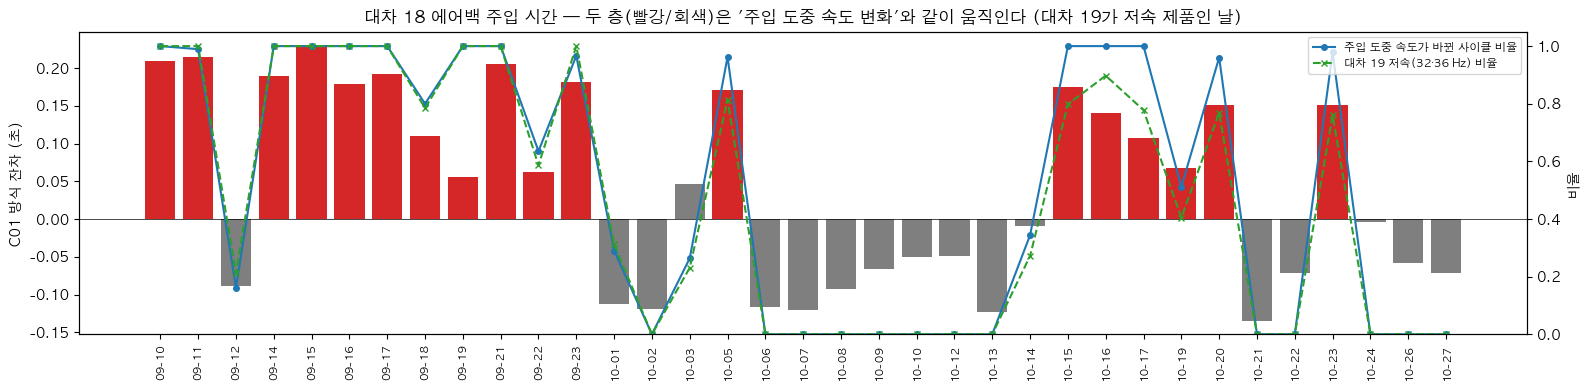

In [23]:
fig, ax = plt.subplots(figsize=(16, 4))
x = range(len(t18))
ax.bar(x, t18["C01 잔차"], color=np.where(t18["속도 바뀐 비율"] > 0.5, "tab:red", "tab:gray"))
ax2 = ax.twinx(); ax2.plot(x, t18["속도 바뀐 비율"], "o-", color="tab:blue", ms=4, label="주입 도중 속도가 바뀐 사이클 비율")
s19 = slow[19]; s19.index = s19.index.strftime("%m-%d")
ax2.plot(x, s19.reindex(t18.index).values, "x--", color="tab:green", ms=5, label="대차 19 저속(32·36 Hz) 비율")
ax.set_xticks(list(x), t18.index, rotation=90, fontsize=8); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("C01 방식 잔차 (초)"); ax2.set_ylabel("비율"); ax2.set_ylim(0, 1.05); ax2.legend(loc="upper right", fontsize=8)
ax.set_title("대차 18 에어백 주입 시간 — 두 층(빨강/회색)은 '주입 도중 속도 변화'와 같이 움직인다 (대차 19가 저속 제품인 날)")
fig.tight_layout(); fig.savefig(FIGS / "C02_wagon18_speedpath.png", dpi=110, bbox_inches="tight")

### 7-3. 0.5초 샘플링 — 주입 시간·노즐 후진 시간은 계단 값

DB 샘플 간격은 약 0.5초다. 사이클 지표(시각의 차이)도 0.5초 계단으로만 찍힌다. 주입 시간은 사이클마다 대략 **2.1초 또는 2.6초** 둘 중 하나다. 노즐 후진 시간은 **0 또는 0.5초**다.
주입 SOL은 노즐 후진감지 OFF에서 0.5초 뒤 켜지므로 두 값은 같은 경계를 나눠 갖는다. 한쪽이 한 칸 길게 찍히면 다른 쪽이 한 칸 짧다.
→ 날별 평균에서 주입 시간만 보면 샘플링 위상 탓에 흔들린다. **주입 시간 + 노즐 후진 시간**의 합이 더 안정적이다.

In [24]:
raw26 = db.fetch_day("2026-10-26", TAGS, group="conveyor")
print("DB 샘플 간격 (10-26):", raw26.index.to_series().diff().dt.total_seconds().round(2).value_counts().head(4).to_dict())
x = AB[(AB.path == "400→400")].dropna(subset=["air_time", "nozzle_rev_time_1"])
print("주입 시간 값:", x.air_time.round(1).value_counts().head(5).to_dict())
print("노즐 후진 시간 값:", x.nozzle_rev_time_1.round(1).value_counts().head(3).to_dict())
print("사이클별 상관 (주입 시간 vs 노즐 후진 시간 1):", round(x.air_time.corr(x.nozzle_rev_time_1), 2))

DB 샘플 간격 (10-26): {0.51: 39598, 0.52: 36778, 0.53: 16501, 0.5: 12379}
주입 시간 값: {2.6: 45216, 2.1: 33013, 2.0: 2527, 2.7: 1367, 2.5: 1184}
노즐 후진 시간 값: {0.5: 46803, 0.0: 36502, 0.6: 111}
사이클별 상관 (주입 시간 vs 노즐 후진 시간 1): -0.61


### 7-4. 속도 경로로 보정한 6건 표 (C01 5-1 다시 계산)

잔차 기준을 "그날 같은 **속도 경로**(시작 Hz → 주입 중 최저 Hz) 평균"으로 바꾼다. 주입 시간만 보는 것과, 주입 시간 + 노즐 후진 시간(평균) 합을 같이 본다.

In [25]:
AB["air_noz"] = AB.air_time + AB[["nozzle_rev_time_1", "nozzle_rev_time_2"]].mean(axis=1)
CASES = [  # (작업ID, 대차, 누수가 있던 날들, 조치) — C01 노트북 7-6과 같다
    ("M-01-12-3", 35, ["09-10"], "CUSHG 하단 호스 교체"),
    ("C-062", 2, ["09-15"], "에어 누수 점검"),
    ("M-01-04-3", 10, ["09-22"], "CUSHG 에어백 라인 호스 절단·피팅"),
    ("C-122/124", 34, ["10-05"], "에어백 교체"),
    ("X-029 (C01)", 28, ["10-17", "10-19", "10-20", "10-21"], "리미트 스위치 점검 / 10-22 해소"),
    ("G-02-003 (C02)", 18, ["10-26"], "에어백 점검"),
]
def case_table(R, label):
    rows = []
    for job, w, leak, act in CASES:
        s = R.loc[w].dropna(); on, off = s[s.index.isin(leak)], s[~s.index.isin(leak)]
        sd = 1.4826 * (off - off.median()).abs().median()
        rows.append({"작업ID": job, "대차": w, f"{label} 누수일": on.mean(), f"{label} 평소": off.median(),
                     f"{label} 흔들림": sd, f"{label} 차이/흔들림": (on.mean() - off.median()) / sd})
    return pd.DataFrame(rows).set_index(["작업ID", "대차"])

R_path = resid_table(AB, "air_time", "path", min_n=100)
R_sum = resid_table(AB, "air_noz", "path", min_n=100)
spread = lambda R: R.apply(lambda s: 1.4826 * (s.dropna() - s.dropna().median()).abs().median(), axis=1)
print("대차 18 흔들림 — C01 방식:", round(spread(R_c01)[18], 3), "/ 속도 경로:", round(spread(R_path)[18], 3),
      "/ 42대 중앙값(속도 경로):", round(spread(R_path).median(), 3))
pd.concat([case_table(R_c01, "C01방식"), case_table(R_path, "주입"), case_table(R_sum, "주입+노즐")], axis=1)[
    [c for c in ["C01방식 차이/흔들림", "주입 누수일", "주입 평소", "주입 흔들림", "주입 차이/흔들림", "주입+노즐 차이/흔들림"]]].round(3)

대차 18 흔들림 — C01 방식: 0.184 / 속도 경로: 0.023 / 42대 중앙값(속도 경로): 0.035


,,C01방식 차이/흔들림,주입 누수일,주입 평소,주입 흔들림,주입 차이/흔들림,주입+노즐 차이/흔들림
작업ID,대차,,,,,,
M-01-12-3,35,-1.773,-0.040,0.001,0.025,-1.639,-1.378
C-062,2,-0.822,-0.024,0.004,0.044,-0.640,-0.277
M-01-04-3,10,-0.738,-0.023,-0.013,0.063,-0.146,-0.235
C-122/124,34,0.257,0.065,-0.026,0.071,1.280,1.550
X-029 (C01),28,-0.391,0.022,-0.003,0.039,0.649,0.962
G-02-003 (C02),18,-0.639,-0.002,-0.061,0.020,3.000,-0.534


In [26]:
# 대차 18 날별 — 속도 경로 보정 주입 시간과 노즐 후진 시간이 서로 시간을 주고받는다 (10-17·10-24·10-26)
T = pd.DataFrame({"주입": R_path.loc[18], "노즐후진": resid_table(AB, "nozzle_rev_time_1", "path", min_n=100).loc[18],
                  "주입+노즐": R_sum.loc[18]})
T.loc["10-13":].round(3).T

,10-13,10-14,10-15,10-16,10-17,10-19,10-20,10-21,10-22,10-23,10-24,10-26,10-27
주입,-0.090,-0.056,-0.073,-0.044,0.021,-0.075,-0.048,-0.081,-0.023,-0.080,0.041,-0.002,-0.012
노즐후진,0.072,0.058,0.033,0.058,-0.048,0.008,0.066,0.053,-0.018,0.022,-0.019,-0.038,0.013
주입+노즐,-0.015,0.004,-0.035,0.011,-0.025,-0.070,0.009,-0.036,-0.041,-0.064,0.022,-0.046,-0.006


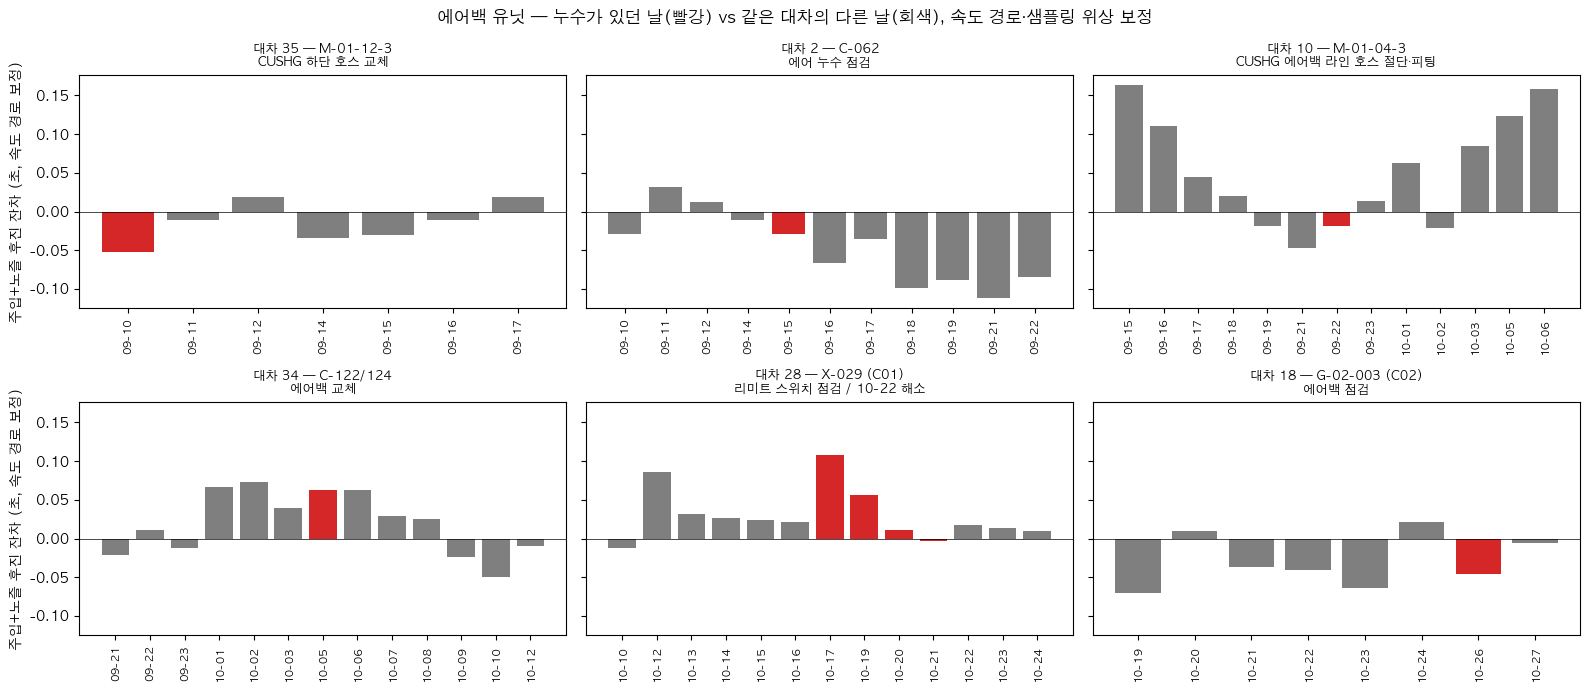

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)
for ax, (job, w, leak, act) in zip(axes.flat, CASES):
    s = R_sum.loc[w].dropna()
    d0 = list(s.index).index(leak[0]) if leak[0] in s.index else 0
    sel = s.iloc[max(0, d0 - 6): d0 + 7]
    ax.bar(range(len(sel)), sel.values, color=["tab:red" if c in leak else "tab:gray" for c in sel.index])
    ax.set_xticks(range(len(sel)), sel.index, rotation=90, fontsize=8)
    ax.axhline(0, color="k", lw=0.5); ax.set_title(f"대차 {w} — {job}\n{act}", fontsize=9)
for a in axes[:, 0]: a.set_ylabel("주입+노즐 후진 잔차 (초, 속도 경로 보정)")
fig.suptitle("에어백 유닛 — 누수가 있던 날(빨강) vs 같은 대차의 다른 날(회색), 속도 경로·샘플링 위상 보정")
fig.tight_layout(); fig.savefig(FIGS / "C02_leak_cases_airnoz.png", dpi=110, bbox_inches="tight")

### 7-5. 부수 — 대차 번호 태그가 한 틱 늦는 통과가 17%

재생 통과표에서 **같은 센서·같은 대차 번호가 30초 안에 두 번** 찍히는 통과가 약 15%다(대차 간격은 약 13초).
코어는 P00140 카운터(R00040)가 리셋되는 틱의 `Now_Actual_Wagon_Num`을 대차 번호로 쓴다(`core_realtime.py` 1·2차 리셋).
태그가 같은 틱에 안 바뀌고 다음 틱(0.5초 뒤)에 바뀌면 그 통과는 **앞 대차 번호**를 받는다.

In [28]:
r = raw26[["R00040", "Now_Actual_Wagon_Num"]].ffill()
c, wn = r.R00040.values, r.Now_Actual_Wagon_Num.values
reset = np.where(np.diff(c) < -50)[0] + 1
reset = reset[(reset > 0) & (reset < len(wn) - 2)]
print(f"10-26 P00140 리셋 {len(reset)}번 — 태그가 같은 틱에 바뀜 {np.mean(wn[reset] != wn[reset - 1]):.3f}, "
      f"다음 틱에 바뀜 {np.mean(wn[reset + 1] != wn[reset]):.3f}")
P2 = CONT["passes"].sort_values(["sensor", "wagon", "t"])
dt = P2.groupby(["sensor", "wagon"]).t.diff().dt.total_seconds()
print("같은 센서·대차 번호가 30초 안에 다시 찍힌 통과 비율:", round((dt < 30).mean(), 3))

10-26 P00140 리셋 4558번 — 태그가 같은 틱에 바뀜 0.831, 다음 틱에 바뀜 0.169
같은 센서·대차 번호가 30초 안에 다시 찍힌 통과 비율: 0.153


### 7-6. 결론

1. **대차 18의 큰 흔들림(0.184초)은 대차 18의 문제가 아니다.** 다음 대차 19가 저속 제품을 실은 날에는 18번 주입 도중 컨베이어가 40 → 32·36 Hz로 느려진다. C01 방식은 스톱퍼 ON 시점의 속도만 보므로 이것을 못 거른다. 속도 경로로 보정하면 18번의 흔들림은 0.02 ~ 0.04초로 다른 대차와 같다.
2. 사이클 지표는 0.5초 계단 값이다. 주입 시간과 노즐 후진 시간은 같은 경계를 나눠 가지므로 둘의 합이 더 안정적이다.
3. 보정한 뒤에도 **6건 모두 누수일 값이 평소 흔들림 안이다**(주입+노즐 합 기준). 주입 시간 하나만 보면 C02가 +3.0으로 튀지만, 같은 날 노즐 후진 시간이 같은 만큼 줄어 합은 그대로다(샘플링 위상). 조치 뒤 10-27에도 같은 값이라 조치와도 무관하다.
4. → C01 5-1의 결론(주입 시간은 에어 누수 피처가 아니다)은 그대로다. 근거 표는 7-4의 보정판이 더 정확하다.
5. 부수: 대차 번호 태그 지연으로 통과의 약 17%가 앞 대차 번호를 받는다. 대차별 칸에 이웃 대차 통과가 섞인다(모델 수정 예정에 기록).

정리본: [`cases/C02.md`](cases/C02.md).